#### Inferência Causal

##### Hipótese central

Após a implantação do PSI, municípios com maior exposição prévia ao crédito do Finame apresentaram crescimento relativamente maior do emprego formal e da massa salarial real. O mecanismo proposto é o estímulo ao investimento produtivo por meio do barateamento do crédito para máquinas e equipamentos.

##### Objetivo central

Estimar a variação diferencial do emprego formal e da massa salarial real após o PSI, explorando diferenças predeterminadas na exposição municipal ao Finame antes de 2009.

##### Objetivos específicos

1. Construir um painel município-ano para 2005–2013, combinando desembolsos do BNDES/Finame, indicadores da RAIS e população do IBGE.
2. Construir uma medida de exposição pré-PSI com os desembolsos do Finame de 2002–2004, anteriores à janela de análise.
3. Estimar a mudança diferencial pós-PSI segundo a exposição inicial.
4. Estimar um estudo de eventos para examinar as pré-tendências e a dinâmica das diferenças após o programa.
5. Testar se a mudança diferencial pós-PSI aumenta com o nível de exposição inicial, por meio de uma especificação por faixas de exposição.

#### Pacotes & Imports

Instale as dependências do projeto com `python -m pip install -r requirements.txt` no terminal e selecione o mesmo ambiente Python como kernel. Consulte o README para a ordem de execução e os dados.

In [ ]:
from pathlib import Path

# --- Manipulação de dados ---
import numpy as np
import pandas as pd

# --- Estatística e testes de hipótese ---
from scipy import stats                      # testes t, qui-quadrado, normalidade, etc.

# --- Regressões (MQO, DiD, efeitos fixos via fórmula) ---
import statsmodels.api as sm                 # sm.OLS, sm.Logit, sm.add_constant
import statsmodels.formula.api as smf        # smf.ols('y ~ tratado * pos + C(ano)', data=df)
from statsmodels.stats.diagnostic import het_breuschpagan   # heterocedasticidade
from statsmodels.stats.outliers_influence import variance_inflation_factor  # multicolinearidade
from statsmodels.iolib.summary2 import summary_col           # tabela comparando modelos

# --- Dados em painel (efeitos fixos/aleatórios, TWFE para DiD) ---
from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS
from linearmodels.panel import compare as compare_panel

# --- Pareamento / escore de propensão (opcional, PSM + DiD) ---
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

# --- Gráficos (tendências paralelas, event study) ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configurações ---
import warnings
warnings.filterwarnings('ignore')
pd.set_option("display.max_columns", None)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid')

## --- outros 
from datetime import datetime

from unidecode import unidecode

# Funciona com o kernel iniciado na raiz ou na pasta do notebook.
diretorio_atual = Path.cwd().resolve()
raiz_projeto = next(
    (pasta for pasta in (diretorio_atual, *diretorio_atual.parents)
     if (pasta / "requirements.txt").is_file() and (pasta / "objetivos").is_dir()),
    None,
)
if raiz_projeto is None:
    raise FileNotFoundError("Inicie o notebook dentro da pasta do projeto.")
pasta_dados = raiz_projeto / "dados_base's"
if not pasta_dados.is_dir():
    raise FileNotFoundError(f"Coloque as bases na pasta {pasta_dados}. Veja o README.")

In [56]:
data_hora = datetime.now().strftime("%d-%m-%Y_%H-%M")

#### Bases para o painel



O objetivo central é estimar esses efeitos explorando diferenças predeterminadas na exposição municipal ao Finame antes de 2009. Os objetivos específicos são: 
1. construir um painel município-ano para 2005-2013, combinando desembolsos do BNDES/Finame, indicadores da RAIS e população do IBGE; 
2. construir uma medida de exposição pré-PSI com os desembolsos do Finame de 2002-2004, anteriores ao período de análise;  
3. estimar a mudança diferencial pós-PSI segundo a exposição inicial; 
4. estimar um estudo de evento para examinar pré-tendências e a dinâmica dos efeitos; 
5. testar se o efeito cresce com o nível de exposição, por meio de uma especificação por faixas de exposição.


##### df_finame

In [57]:
df_finame = pd.read_excel(pasta_dados / "desembolsos-mensais_Finame.xlsx", sheet_name='sheet_1')

In [58]:
df_finame

,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,municipio,municipio_codigo,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais
0,1995.0000,1.0000,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,CENTRO OESTE,MATO GROSSO,BARRA DO BUGRES,5101704.0000,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,4521720.3700
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1995.0000,1.0000,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,NORTE,AMAZONAS,NOVO AIRAO,1303205.0000,COMﾉRCIO E SERVIﾇOS,TRANSPORTE AQUAVIﾁRIO,INFRAESTRUTURA,OUTROS TRANSPORTES,2099499.9900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
367837,2026.0000,3.0000,INDIRETA,BNDES FINAME,MODERFROTA,NﾃO,PEQUENA,SUL,PARANA,JURANDA,4112959.0000,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203480.0000
367838,2026.0000,3.0000,INDIRETA,BNDES FINAME,MATERIAIS INDUSTRIALIZADOS,NﾃO,MﾉDIA,SUDESTE,ESPIRITO SANTO,SERRA,3205002.0000,COMﾉRCIO E SERVIﾇOS,COMﾉRCIO,COMﾉRCIO E SERVIﾇOS,COMﾉRCIO E SERVIﾇOS,203330.6400
367839,2026.0000,3.0000,INDIRETA,BNDES FINAME,PRONAF INVESTIMENTO,NﾃO,PEQUENA,SUL,SANTA CATARINA,ROMELANDIA,4215208.0000,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203202.0000
367840,2026.0000,3.0000,INDIRETA,BNDES FINAME,PRONAF INVESTIMENTO,NﾃO,PEQUENA,SUDESTE,ESPIRITO SANTO,COLATINA,3201506.0000,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203000.0000


Células vazias e entrega de números inteiros em formato de decimais

Limpar a coluna


contar o que está vazio

In [59]:
df_finame = df_finame.dropna(subset=["municipio_codigo"])

df_finame[["ano", "mes", "municipio_codigo"]].isna().sum()

ano                 0
mes                 0
municipio_codigo    0
dtype: int64

In [60]:
for col in ["ano", "mes", "municipio_codigo"]:
    df_finame[col] = df_finame[col].astype(int)

In [61]:
siglas = {
    "ACRE": "AC", "ALAGOAS": "AL", "AMAPA": "AP",
    "AMAZONAS": "AM", "BAHIA": "BA", "CEARA": "CE",
    "DISTRITO FEDERAL": "DF", "ESPIRITO SANTO": "ES",
    "GOIAS": "GO", "MARANHAO": "MA", "MATO GROSSO": "MT",
    "MATO GROSSO DO SUL": "MS", "MINAS GERAIS": "MG",
    "PARA": "PA", "PARAIBA": "PB", "PARANA": "PR",
    "PERNAMBUCO": "PE", "PIAUI": "PI",
    "RIO DE JANEIRO": "RJ", "RIO GRANDE DO NORTE": "RN",
    "RIO GRANDE DO SUL": "RS", "RONDONIA": "RO",
    "RORAIMA": "RR", "SANTA CATARINA": "SC",
    "SAO PAULO": "SP", "SERGIPE": "SE", "TOCANTINS": "TO"
}

df_finame["uf_sigla"] = (
    df_finame["uf"].map(siglas)
)

In [62]:
df_finame

,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,municipio,municipio_codigo,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais,uf_sigla
0,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,CENTRO OESTE,MATO GROSSO,BARRA DO BUGRES,5101704,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,4521720.3700,MT
4,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,NORTE,AMAZONAS,NOVO AIRAO,1303205,COMﾉRCIO E SERVIﾇOS,TRANSPORTE AQUAVIﾁRIO,INFRAESTRUTURA,OUTROS TRANSPORTES,2099499.9900,AM
5,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,CENTRO OESTE,MATO GROSSO DO SUL,DOURADOS,5003702,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,2064969.2400,MS
6,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,SUDESTE,SAO PAULO,MOGI DAS CRUZES,3530607,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,2058083.2900,SP
7,1995,1,INDIRETA,BNDES FINAME,NaN,NaN,GRANDE,SUDESTE,SAO PAULO,SAO PAULO,3550308,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,1892247.4100,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
367837,2026,3,INDIRETA,BNDES FINAME,MODERFROTA,NﾃO,PEQUENA,SUL,PARANA,JURANDA,4112959,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203480.0000,PR
367838,2026,3,INDIRETA,BNDES FINAME,MATERIAIS INDUSTRIALIZADOS,NﾃO,MﾉDIA,SUDESTE,ESPIRITO SANTO,SERRA,3205002,COMﾉRCIO E SERVIﾇOS,COMﾉRCIO,COMﾉRCIO E SERVIﾇOS,COMﾉRCIO E SERVIﾇOS,203330.6400,ES
367839,2026,3,INDIRETA,BNDES FINAME,PRONAF INVESTIMENTO,NﾃO,PEQUENA,SUL,SANTA CATARINA,ROMELANDIA,4215208,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203202.0000,SC
367840,2026,3,INDIRETA,BNDES FINAME,PRONAF INVESTIMENTO,NﾃO,PEQUENA,SUDESTE,ESPIRITO SANTO,COLATINA,3201506,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,AGROPECUﾁRIA,203000.0000,ES


##### df_PSI

In [63]:
df_PSI = pd.read_excel(pasta_dados / "desembolsos-mensais_PSI.xlsx", sheet_name='desembolsos-mensais_PSI')

df_PSI = df_PSI[df_PSI['ano'].isin([2009, 2010, 2011, 2012, 2013])]

In [64]:
df_PSI

,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,municipio,municipio_codigo,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais
0,2009,8,DIRETA,BNDES FINEM,PSI - BK - Demais Itens,N鬃,GRANDE,NORTE,RONDONIA,PORTO VELHO,1100205,IND湒TRIA DE TRANSFORMAO,MINERAL N鬃 MET簇ICO,INDUSTRIA,OUTRAS,17000000.0000
1,2009,8,DIRETA,BNDES FINEM,PSI - BK - Demais Itens,N鬃,GRANDE,CENTRO OESTE,MATO GROSSO,NOBRES,5105903,IND湒TRIA DE TRANSFORMAO,MINERAL N鬃 MET簇ICO,INDUSTRIA,OUTRAS,8000000.0000
2,2009,8,INDIRETA,BNDES FINAME,PSI - BK - Demais Itens,N鬃,GRANDE,SUDESTE,RIO DE JANEIRO,RIO DE JANEIRO,3304557,COM仂CIO E SERVIS,CONSTRUO,COM仂CIO E SERVIS,COM仂CIO E SERVIS,5061388.7500
3,2009,8,INDIRETA,BNDES FINAME,PSI - BK - Demais Itens,N鬃,GRANDE,SUL,PARANA,CURITIBA,4106902,COM仂CIO E SERVIS,CONSTRUO,COM仂CIO E SERVIS,COM仂CIO E SERVIS,2501578.0000
4,2009,8,INDIRETA,BNDES FINAME,PSI - BK - Demais Itens,N鬃,MICRO,CENTRO OESTE,GOIAS,RIO VERDE,5218805,AGROPECU糠IA,AGROPECU糠IA,AGROPECU糠IA,AGROPECU糠IA,2429100.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
189375,2013,9,DIRETA,BNDES FINEM,PSI - Projetos Transformadores,SIM,GRANDE,SUDESTE,MINAS GERAIS,RIBEIRAO DAS NEVES,3154606,IND湒TRIA DE TRANSFORMAO,"EQUIP INFO, ELETRONICO, 紘ICO",INDUSTRIA,MEC齋ICA,20429555.0100
189376,2013,9,INDIRETA,BNDES FINEM,PSI - Projetos Transformadores,SIM,GRANDE,SUDESTE,MINAS GERAIS,RIBEIRAO DAS NEVES,3154606,IND湒TRIA DE TRANSFORMAO,"EQUIP INFO, ELETRONICO, 紘ICO",INDUSTRIA,MEC齋ICA,6566642.6800
189377,2013,10,DIRETA,BNDES FINEM,PSI - Projetos Transformadores,SIM,GRANDE,SUDESTE,MINAS GERAIS,RIBEIRAO DAS NEVES,3154606,IND湒TRIA DE TRANSFORMAO,"EQUIP INFO, ELETRONICO, 紘ICO",INDUSTRIA,MEC齋ICA,6764000.0000
189378,2013,10,INDIRETA,BNDES FINEM,PSI - Projetos Transformadores,SIM,GRANDE,SUDESTE,MINAS GERAIS,RIBEIRAO DAS NEVES,3154606,IND湒TRIA DE TRANSFORMAO,"EQUIP INFO, ELETRONICO, 紘ICO",INDUSTRIA,MEC齋ICA,2174000.0000


##### df_ipca

In [65]:
df_ipca = pd.read_excel(pasta_dados / "IPCA_STP-20261019203512642.xlsx", sheet_name='IPCA')

df_ipca

,Data,IPCA - Var. % mensal
0,2000-01-01,0.6200
1,2000-02-01,0.1300
2,2000-03-01,0.2200
3,2000-04-01,0.4200
4,2000-05-01,0.0100
...,...,...
175,2014-08-01,0.2500
176,2014-09-01,0.5700
177,2014-10-01,0.4200
178,2014-11-01,0.5100


##### PIB municipal (IBGE)

Carregamos a base de PIB municipal. Na montagem do painel de estimação, usar o PIB per capita de 2005 como controle inicial e o de 2008 como alternativa na análise de sensibilidade.

In [66]:
df_pib_munic_2002_2009 = pd.read_excel(pasta_dados / "PIB dos Municípios - base de dados 2002-2009.xlsx", sheet_name='PIB_dos_Municípios')

df_pib_munic_2002_2009

,Ano,Código da Grande Região,Nome da Grande Região,Código da Unidade da Federação,UF,NOME UF,Código do Município,Nome do Município,Código da Região Rural,Nome da Região Rural,Região rural (segundo classificação do núcleo),Amazônia Legal,Semiárido,"Valor adicionado bruto da Agropecuária, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto da Indústria,\na preços correntes\n(R$ 1.000)","Valor adicionado bruto dos Serviços,\na preços correntes \n- exceto Administração, defesa, educação e saúde públicas e seguridade social\n(R$ 1.000)","Valor adicionado bruto da Administração, defesa, educação e saúde públicas e seguridade social, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto total, \na preços correntes\n(R$ 1.000)","Impostos, líquidos de subsídios, sobre produtos, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto per capita, \na preços correntes\n(R$ 1,00)"
0,2002,1,Norte,11,RO,Rondônia,1100015,Alta Floresta D'Oeste,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,27013.2230,9376.8710,24651.1130,42700.5230,103741.7290,7549.2660,111290.9950,4047.8300
1,2002,1,Norte,11,RO,Rondônia,1100023,Ariquemes,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,28590.1780,99922.9360,161851.5490,116562.1820,406926.8450,42665.9720,449592.8160,5667.3700
2,2002,1,Norte,11,RO,Rondônia,1100031,Cabixi,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,10883.8010,1961.9070,5128.8760,11925.0010,29899.5850,1867.9350,31767.5200,4246.9900
3,2002,1,Norte,11,RO,Rondônia,1100049,Cacoal,5105,Região Rural do Centro Sub-regional de Vilhena...,Região Rural de Centro Sub-regional,Sim,Não,32810.3760,98292.7640,175748.7030,117968.3030,424820.1460,49622.9510,474443.0970,6353.2700
4,2002,1,Norte,11,RO,Rondônia,1100056,Cerejeiras,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,11283.7930,6651.4750,25306.0090,27731.3660,70972.6430,8200.9710,79173.6140,4442.4700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44496,2009,5,Centro-oeste,52,GO,Goiás,5222005,Vianópolis,5204,Região Rural da Metrópole Nacional de Brasília,Região Rural de Metrópole Nacional,Não,Não,53529.0850,14813.1680,58617.5850,26216.1580,153175.9960,11160.3410,164336.3370,12807.7600
44497,2009,5,Centro-oeste,52,GO,Goiás,5222054,Vicentinópolis,5206,Região Rural do Centro Sub-regional de Itumbiara,Região Rural de Centro Sub-regional,Não,Não,63465.0400,11101.4180,38070.9060,13974.0180,126611.3820,6819.0300,133430.4130,21898.9700
44498,2009,5,Centro-oeste,52,GO,Goiás,5222203,Vila Boa,5203,Região Rural do Centro de Zona de Campos Belos,Região Rural de Centro de zona,Não,Não,25391.5200,12652.8350,19921.0140,11463.2990,69428.6690,3938.7130,73367.3810,16026.0800
44499,2009,5,Centro-oeste,52,GO,Goiás,5222302,Vila Propício,5202,Região Rural do Centro Sub-regional de Anápolis,Região Rural de Centro Sub-regional,Não,Não,49814.2180,26168.4280,16793.2110,11847.7400,104623.5970,2501.7940,107125.3910,19989.8100


In [67]:
df_pib_munic_2010_2023 = pd.read_excel(pasta_dados / "PIB dos Municípios - base de dados 2010-2023.xlsx", sheet_name='PIB dos Municípios')

df_pib_munic_2010_2023

,Ano,Código da Grande Região,Nome da Grande Região,Código da Unidade da Federação,Sigla da Unidade da Federação,Nome da Unidade da Federação,Código do Município,Nome do Município,Região Metropolitana,Código da Mesorregião,Nome da Mesorregião,Código da Microrregião,Nome da Microrregião,Código da Região Geográfica Imediata,Nome da Região Geográfica Imediata,Município da Região Geográfica Imediata,Código da Região Geográfica Intermediária,Nome da Região Geográfica Intermediária,Município da Região Geográfica Intermediária,Código Concentração Urbana,Nome Concentração Urbana,Tipo Concentração Urbana,Código Arranjo Populacional,Nome Arranjo Populacional,Hierarquia Urbana,Hierarquia Urbana (principais categorias),Código da Região Rural,Nome da Região Rural,Região rural (segundo classificação do núcleo),Amazônia Legal,Semiárido,Cidade-Região de São Paulo,"Valor adicionado bruto da Agropecuária, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto da Indústria,\na preços correntes\n(R$ 1.000)","Valor adicionado bruto dos Serviços,\na preços correntes \n- exceto Administração, defesa, educação e saúde públicas e seguridade social\n(R$ 1.000)","Valor adicionado bruto da Administração, defesa, educação e saúde públicas e seguridade social, \na preços correntes\n(R$ 1.000)","Valor adicionado bruto total, \na preços correntes\n(R$ 1.000)","Impostos, líquidos de subsídios, sobre produtos, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto, \na preços correntes\n(R$ 1.000)","Produto Interno Bruto per capita, \na preços correntes\n(R$ 1,00)",Atividade com maior valor adicionado bruto,Atividade com segundo maior valor adicionado bruto,Atividade com terceiro maior valor adicionado bruto
0,2010,1,Norte,11,RO,Rondônia,1100015,Alta Floresta D'Oeste,NaN,1102,Leste Rondoniense,11006,Cacoal,110005,Cacoal,do Entorno,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro Local,Centro Local,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,Não,69260.3910,16118.5340,62496.1850,93244.6560,241119.7670,20957.1110,262076.8780,10731.1800,"Administração, defesa, educação e saúde públic...","Pecuária, inclusive apoio à pecuária",Demais serviços
1,2010,1,Norte,11,RO,Rondônia,1100023,Ariquemes,NaN,1102,Leste Rondoniense,11003,Ariquemes,110002,Ariquemes,Polo,1101,Porto Velho,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro Sub-Regional A,Centro Sub-Regional,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,Não,73711.6430,287138.5850,494946.2670,343867.7310,1199664.2270,165029.5530,1364693.7800,15103.8600,"Administração, defesa, educação e saúde públic...",Demais serviços,Comércio e reparação de veículos automotores e...
2,2010,1,Norte,11,RO,Rondônia,1100031,Cabixi,NaN,1102,Leste Rondoniense,11008,Colorado do Oeste,110006,Vilhena,do Entorno,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro Local,Centro Local,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não,Não,24300.8220,3252.5060,12677.2100,25170.2350,65400.7720,4210.3420,69611.1140,11033.6200,"Administração, defesa, educação e saúde públic...","Pecuária, inclusive apoio à pecuária",Demais serviços
3,2010,1,Norte,11,RO,Rondônia,1100049,Cacoal,NaN,1102,Leste Rondoniense,11006,Cacoal,110005,Cacoal,Polo,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Capital Regional C,Capital Regional,5105,Região Rural do Centro Sub-regional de Vilhena...,Região Rural de Centro Sub-regional,Sim,Não,Não,95259.2030,182051.5370,465447.3250,298454.3090,1041212.3740,145281.7170,1186494.0910,15095.1500,"Administração, defesa, educação e saúde públic...",Demais serviços,Comércio e reparação de veículos automotores e...
4,2010,1,Norte,11,RO,Rondônia,1100056,Cerejeiras,NaN,1102,Leste Rondoniense,11008,Colorado do Oeste,110006,Vilhena,do Entorno,1102,Ji-Paraná,do Entorno,NaN,NaN,NaN,NaN,NaN,Centro de Zona B,Centro de Zona,1101,Região Rural da Capital Regional de Porto Velho,Região Rural de Capital Regional,Sim,Não

##### Emprego e remuneração (RAIS)

- **Emprego formal (`emprego`)** — estoque de vínculos ativos em 31 de dezembro (`estoque_emprego`).
- **Massa salarial real (`massa_salarial`)** — construir a proxy com uma medida de remuneração compatível com o estoque de vínculos e expressá-la em reais de dezembro de 2008. A deflação implementada para o Finame é uma etapa separada.

A especificação principal prevê `ln_emprego` e `ln_massa_salarial` para estimar mudanças proporcionais por desvio-padrão de exposição. Antes de aplicar o log, verificar zeros, valores ausentes e a composição da amostra. Em níveis, a análise mede mudanças absolutas.

Para a análise de sensibilidade, calcular o crescimento do emprego de 2005 a 2008 pela diferença dos logs do estoque. Como essa medida usa o próprio desfecho na janela do teste, incluí-la pode atenuar mecanicamente as pré-tendências observadas.

In [68]:
df_rais = pd.read_excel(pasta_dados / "rais_empr_remuner_2000_2014.xlsx", sheet_name='RAIS')
df_rais

,ano,sigla_uf,id_municipio,subsetor_ibge,emprego_3112,prop_homens,idade_media,prop_mulheres,prop_preta,prop_parda,prop_negra,valor_salario_contratual,valor_remuneracao_media,valor_remuneracao_dezembro
0,2001,IGNORADO,NaN,NaN,39,0.5897,41.2308,0.4103,0.0000,0.0000,0.0000,NaN,807.8531,833.0259
1,2002,IGNORADO,NaN,NaN,54,0.5000,37.8704,0.5000,0.0000,0.0000,0.0000,NaN,802.8307,782.9515
2,2003,IGNORADO,NaN,NaN,2,0.5000,25.5000,0.5000,0.0000,0.0000,0.0000,NaN,451.7350,569.8800
3,2004,IGNORADO,NaN,NaN,1,0.0000,28.0000,1.0000,0.0000,0.0000,0.0000,NaN,403.3200,413.3200
4,2005,IGNORADO,NaN,NaN,5,0.4000,35.4000,0.6000,0.0000,0.0000,0.0000,NaN,1231.6060,652.6220
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83304,2010,DF,5300108.0000,NaN,1099832,0.6369,35.7004,0.3631,0.0242,0.2275,0.2516,NaN,3274.0976,3609.4194
83305,2011,DF,5300108.0000,NaN,1156908,0.6327,35.8587,0.3673,0.0246,0.2364,0.2610,NaN,3417.8013,3695.1621
83306,2012,DF,5300108.0000,NaN,1181649,0.6277,36.1439,0.3723,0.0242,0.2379,0.2621,NaN,3639.5494,3888.0370
83307,2013,DF,5300108.0000,NaN,1302284,0.6339,35.5421,0.3661,0.0223,0.2341,0.2564,NaN,3782.9309,4097.1058


In [69]:
df_rais.columns.tolist()

['ano',
 'sigla_uf',
 'id_municipio',
 'subsetor_ibge',
 'emprego_3112',
 'prop_homens',
 'idade_media',
 'prop_mulheres',
 'prop_preta',
 'prop_parda',
 'prop_negra',
 'valor_salario_contratual',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro']

In [70]:
df_rais = df_rais.dropna(subset=["id_municipio"])

# rais[["id_municipio", "valor_salario_contratual", "valor_remuneracao_media",  "valor_remuneracao_dezembro"]].isna().sum()

In [71]:
for col in ["id_municipio"]:
    df_rais[col] = df_rais[col].astype(int)

df_rais[col].dtypes


dtype('int64')

In [72]:
# rais = rais[['ano',
#              'sigla_uf',
#              'id_municipio',
#              'emprego_3112',
#              'prop_homens',
#              'idade_media',
#              'prop_mulheres',
#              'prop_preta',
#              'prop_parda',
#              'prop_negra',
#              'valor_remuneracao_media',
#              'valor_remuneracao_dezembro']]

df_rais.reset_index(drop=True, inplace=True)

df_rais

,ano,sigla_uf,id_municipio,subsetor_ibge,emprego_3112,prop_homens,idade_media,prop_mulheres,prop_preta,prop_parda,prop_negra,valor_salario_contratual,valor_remuneracao_media,valor_remuneracao_dezembro
0,2000,RO,1100015,NaN,1196,0.5677,31.1931,0.4323,0.0000,0.0000,0.0000,NaN,287.4081,290.0647
1,2001,RO,1100015,NaN,1185,0.5789,31.6574,0.4211,0.0000,0.0000,0.0000,NaN,330.5743,323.1142
2,2002,RO,1100015,NaN,1440,0.5785,32.2160,0.4215,0.0000,0.0000,0.0000,NaN,438.4699,409.4442
3,2003,RO,1100015,NaN,1629,0.5856,32.4205,0.4144,0.0000,0.0000,0.0000,NaN,473.1530,503.8662
4,2004,RO,1100015,NaN,1610,0.6050,32.2075,0.3950,0.0000,0.0000,0.0000,NaN,520.5894,533.4424
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83297,2010,DF,5300108,NaN,1099832,0.6369,35.7004,0.3631,0.0242,0.2275,0.2516,NaN,3274.0976,3609.4194
83298,2011,DF,5300108,NaN,1156908,0.6327,35.8587,0.3673,0.0246,0.2364,0.2610,NaN,3417.8013,3695.1621
83299,2012,DF,5300108,NaN,1181649,0.6277,36.1439,0.3723,0.0242,0.2379,0.2621,NaN,3639.5494,3888.0370
83300,2013,DF,5300108,NaN,1302284,0.6339,35.5421,0.3661,0.0223,0.2341,0.2564,NaN,3782.9309,4097.1058


In [73]:
# rais["id_municipio"] = rais["id_municipio"].astype(int)

##### População municipal (IBGE)

A tabela de 2002–2004 fornece os denominadores anuais para calcular os desembolsos históricos por habitante. Para usar população inicial como controle na regressão, ainda é preciso vincular a população de 2005.

In [74]:
df_IBGE_pop = pd.read_excel(pasta_dados / "IBGE_pop_municipios.xlsx", sheet_name='IBGE_pop_municipios')

df_IBGE_pop

,ANOS,SIGLA,U.F.,MUNIC,MUNICÍPIOS,POP
0,2002,GO,52,5,Abadia de Goiás,5415
1,2003,GO,52,5,Abadia de Goiás,5621
2,2004,GO,52,5,Abadia de Goiás,6054
3,2002,MG,31,10,Abadia dos Dourados,6436
4,2003,MG,31,10,Abadia dos Dourados,6432
...,...,...,...,...,...,...
16679,2003,MA,21,1400,Zé Doca,48565
16680,2004,MA,21,1400,Zé Doca,50183
16681,2002,SC,42,1985,Zortéa,2703
16682,2003,SC,42,1985,Zortéa,2736


.copy()

Tornando independente e tudo se altera sem mexer na variavél anterior

In [75]:
df_ibge = df_IBGE_pop.copy()

In [76]:
df_ibge.columns.tolist()

['ANOS', 'SIGLA', 'U.F.', 'MUNIC', 'MUNICÍPIOS', 'POP']

In [77]:
# # df_ibge.pd.to_numeric(df_ibge['COD.1'], errors='coerce')

# df_ibge['COD.1'].astype(float)

In [78]:
df_ibge.dtypes

ANOS           int64
SIGLA         object
U.F.           int64
MUNIC          int64
MUNICÍPIOS    object
POP            int64
dtype: object

In [79]:
# df_ibge = df_ibge.reset_index(drop=True)

In [80]:
df_ibge = df_ibge.rename(columns={
    "ANOS": "ano",
    "SIGLA": "uf",
    "POP": "População estimada"
})

In [81]:
df_ibge

,ano,uf,U.F.,MUNIC,MUNICÍPIOS,População estimada
0,2002,GO,52,5,Abadia de Goiás,5415
1,2003,GO,52,5,Abadia de Goiás,5621
2,2004,GO,52,5,Abadia de Goiás,6054
3,2002,MG,31,10,Abadia dos Dourados,6436
4,2003,MG,31,10,Abadia dos Dourados,6432
...,...,...,...,...,...,...
16679,2003,MA,21,1400,Zé Doca,48565
16680,2004,MA,21,1400,Zé Doca,50183
16681,2002,SC,42,1985,Zortéa,2703
16682,2003,SC,42,1985,Zortéa,2736


#### (ii) Construção da exposição pré-PSI

3.1 Estratégia de identificação


"Utiliza-se o método de diferença em diferenças (DiD), que compara a variação do emprego e da massa salarial antes e depois de 2009 entre municípios com diferentes níveis de exposição ao Finame (Gertler et al., 2018; Cunningham, 2021). A mudança observada nos municípios menos expostos indica qual teria sido a mudança dos mais expostos sem a política, e a diferença entre as duas mudanças é atribuída ao programa (Cunningham, 2021; Gertler et al., 2018; Ferraro, 2009; Holland, 1985). Vale frisar que não é possível adotar uma variável dummy neste estudo, pois a intervenção atingiu todos os municípios na mesma data, julho de 2009. Por isso, segue-se Coleman e Feler (2014), que permitem que a intensidade do tratamento varie entre localidades. Assim, os municípios mais expostos são os mais afetados pelo choque, e os menos expostos fazem o papel de comparação.
O método DiD explora três características da intervenção: um choque comum e datado, que é a implantação do PSI em 2009; um painel com anos anteriores ao choque; e uma medida de exposição definida antes do programa, que varia entre municípios. O desenho é, portanto, um DiD com tratamento contínuo, no qual a dose é a exposição pré-determinada 𝑍 (Callaway; Goodman-Bacon; Sant'Anna, 2024)." (pág. 6)

##### df_FINAME_pre_exposicao_2002_2004

In [107]:
df_finame_pre_exposure = df_finame.copy()

In [108]:
df_finame_pre_exposure = df_finame[
    (df_finame["ano"] >= 2002) &
    (df_finame["ano"] <= 2004)
].copy()

df_finame_pre_exposure = df_finame_pre_exposure.rename(
    columns={
        "municipio": "Municipios",
        "municipio_codigo": "id_municipio"
    }
)

print("Total de registros:", len(df_finame_pre_exposure))
print("Duplicações:", df_finame_pre_exposure.duplicated().sum())

df_finame_pre_exposure = df_finame_pre_exposure.reset_index()

Total de registros: 21391
Duplicações: 0


In [109]:
df_finame_pre_exposure

,index,ano,mes,forma_de_apoio,produto,instrumento_financeiro,inovacao,porte_de_empresa,regiao,uf,Municipios,id_municipio,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,desembolsos_reais,uf_sigla
0,23546,2002,1,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUDESTE,ESPIRITO SANTO,VITORIA,3205309,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,14264832.0000,ES
1,23547,2002,1,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,NORTE,PARA,ORIXIMINA,1505304,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,12246392.6700,PA
2,23548,2002,1,INDIRETA,BNDES FINAME,OUTROS,NﾃO,MﾉDIA,SUDESTE,SAO PAULO,SAO PAULO,3550308,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,4843518.3400,SP
3,23549,2002,1,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUDESTE,MINAS GERAIS,OURO BRANCO,3145901,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,4643467.8700,MG
4,23550,2002,1,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUDESTE,SAO PAULO,SAO PAULO,3550308,COMﾉRCIO E SERVIﾇOS,ELETRICIDADE E GﾁS,INFRAESTRUTURA,ENERGIA ELﾉTRICA,4093336.4000,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21386,48338,2004,12,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUDESTE,SAO PAULO,SUMARE,3552403,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,360869.7300,SP
21387,48342,2004,12,INDIRETA,BNDES FINAME,OUTROS,NﾃO,MﾉDIA,SUL,RIO GRANDE DO SUL,CANOAS,4304606,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,348600.0000,RS
21388,48365,2004,12,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUL,SANTA CATARINA,LAGES,4209300,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,299237.5500,SC
21389,48409,2004,12,INDIRETA,BNDES FINAME,OUTROS,NﾃO,GRANDE,SUL,SANTA CATARINA,SAO LUDGERO,4217006,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BORRACHA E PLﾁSTICO,INDUSTRIA,OUTRAS,228000.0000,SC


##### df_finame_pre_expo_popul_ibge

A população do IBGE é vinculada por ano e pelo código municipal de seis dígitos, formado pelos códigos de UF e município. No Finame, o sétimo dígito é o verificador.

In [110]:
df_ibge = df_ibge.copy()

In [111]:
df_ibge["codigo_ibge_6"] = (
    df_ibge["U.F."].astype(int) * 10_000 + df_ibge["MUNIC"].astype(int)
)

In [112]:
df_ibge

,ano,uf,U.F.,MUNIC,MUNICÍPIOS,População estimada,Municipios,codigo_ibge_6
0,2002,GO,52,5,Abadia de Goiás,5415,ABADIA DE GOIAS,520005
1,2003,GO,52,5,Abadia de Goiás,5621,ABADIA DE GOIAS,520005
2,2004,GO,52,5,Abadia de Goiás,6054,ABADIA DE GOIAS,520005
3,2002,MG,31,10,Abadia dos Dourados,6436,ABADIA DOS DOURADOS,310010
4,2003,MG,31,10,Abadia dos Dourados,6432,ABADIA DOS DOURADOS,310010
...,...,...,...,...,...,...,...,...
16679,2003,MA,21,1400,Zé Doca,48565,ZE DOCA,211400
16680,2004,MA,21,1400,Zé Doca,50183,ZE DOCA,211400
16681,2002,SC,42,1985,Zortéa,2703,ZORTEA,421985
16682,2003,SC,42,1985,Zortéa,2736,ZORTEA,421985


In [113]:
df_finame_pre_exposure.columns.tolist()

['index',
 'ano',
 'mes',
 'forma_de_apoio',
 'produto',
 'instrumento_financeiro',
 'inovacao',
 'porte_de_empresa',
 'regiao',
 'uf',
 'Municipios',
 'id_municipio',
 'setor_cnae',
 'subsetor_cnae_agrupado',
 'setor_bndes',
 'subsetor_bndes',
 ' desembolsos_reais ',
 'uf_sigla']

In [114]:
df_finame_pre_exposure = df_finame_pre_exposure.rename(columns={"uf_sigla": "uf",
                                                                "uf": "Estado"  
                                                                })

In [115]:
df_ibge.columns.tolist()

['ano',
 'uf',
 'U.F.',
 'MUNIC',
 'MUNICÍPIOS',
 'População estimada',
 'Municipios',
 'codigo_ibge_6']

In [116]:
df_merge_pop = df_finame_pre_exposure.assign(
    codigo_ibge_6=df_finame_pre_exposure["id_municipio"] // 10
).merge(
    df_ibge[["ano", "codigo_ibge_6", "População estimada"]],
    on=["ano", "codigo_ibge_6"],
    how="left",
    validate="many_to_one",
)

In [117]:
df_merge_pop.columns.tolist()

['index',
 'ano',
 'mes',
 'forma_de_apoio',
 'produto',
 'instrumento_financeiro',
 'inovacao',
 'porte_de_empresa',
 'regiao',
 'Estado',
 'Municipios',
 'id_municipio',
 'setor_cnae',
 'subsetor_cnae_agrupado',
 'setor_bndes',
 'subsetor_bndes',
 ' desembolsos_reais ',
 'uf',
 'codigo_ibge_6',
 'População estimada']

In [118]:
# 1. Remover espaços dos nomes das colunas
df_merge_pop.columns = df_merge_pop.columns.str.strip()

# 2. Renomear as colunas
df_merge_pop = df_merge_pop.rename(columns={
    "desembolsos_reais": "R$_finame"
})

In [119]:
df_merge_pop.columns.tolist()

['index',
 'ano',
 'mes',
 'forma_de_apoio',
 'produto',
 'instrumento_financeiro',
 'inovacao',
 'porte_de_empresa',
 'regiao',
 'Estado',
 'Municipios',
 'id_municipio',
 'setor_cnae',
 'subsetor_cnae_agrupado',
 'setor_bndes',
 'subsetor_bndes',
 'R$_finame',
 'uf',
 'codigo_ibge_6',
 'População estimada']

In [120]:
df_merge_pop = df_merge_pop[[
    'ano',
    'mes',
    'uf',
    'id_municipio',
    'Municipios',
    'População estimada',
    'porte_de_empresa',
    'setor_cnae',
    'subsetor_cnae_agrupado',
    'setor_bndes',
    'subsetor_bndes',
    'R$_finame'
]].copy()

df_merge_pop

,ano,mes,uf,id_municipio,Municipios,População estimada,porte_de_empresa,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,R$_finame
0,2002,1,ES,3205309,VITORIA,299357,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,14264832.0000
1,2002,1,PA,1505304,ORIXIMINA,49945,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,12246392.6700
2,2002,1,SP,3550308,SAO PAULO,10600060,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,4843518.3400
3,2002,1,MG,3145901,OURO BRANCO,31006,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,4643467.8700
4,2002,1,SP,3550308,SAO PAULO,10600060,GRANDE,COMﾉRCIO E SERVIﾇOS,ELETRICIDADE E GﾁS,INFRAESTRUTURA,ENERGIA ELﾉTRICA,4093336.4000
...,...,...,...,...,...,...,...,...,...,...,...,...
21386,2004,12,SP,3552403,SUMARE,225307,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,360869.7300
21387,2004,12,RS,4304606,CANOAS,324994,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,348600.0000
21388,2004,12,SC,4209300,LAGES,165068,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,299237.5500
21389,2004,12,SC,4217006,SAO LUDGERO,9911,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BORRACHA E PLﾁSTICO,INDUSTRIA,OUTRAS,228000.0000


##### Deflacionando - IPCA

Dezembro de 2008 é uma escolha metodologicamente interessante porque representa o encerramento do ano anterior à implementação do PSI, lançado em 2009.

Isso significa que podemos expressar todos os desembolsos em reais de dezembro de 2008, criando uma referência monetária comum anterior à intervenção.

Mês-base da deflação (dezembro de 2008): determina o poder de compra em que esses desembolsos serão expressos.

In [121]:
df_ipca = df_ipca.copy()

df_ipca

,ano,mes,Data,IPCA - Var. % mensal,fator_mensal,indice_ipca,fator_deflacao_dez_2008
0,2000,1,2000-01-01,0.6200,1.0062,100.6200,1.8098
1,2000,2,2000-02-01,0.1300,1.0013,100.7508,1.8075
2,2000,3,2000-03-01,0.2200,1.0022,100.9725,1.8035
3,2000,4,2000-04-01,0.4200,1.0042,101.3965,1.7960
4,2000,5,2000-05-01,0.0100,1.0001,101.4067,1.7958
...,...,...,...,...,...,...,...
175,2014,8,2014-08-01,0.2500,1.0025,249.8270,0.7289
176,2014,9,2014-09-01,0.5700,1.0057,251.2510,0.7248
177,2014,10,2014-10-01,0.4200,1.0042,252.3063,0.7218
178,2014,11,2014-11-01,0.5100,1.0051,253.5930,0.7181


.cumprod(), que significa produto acumulado.

multiplica progressivamente os fatores mensais para construir a trajetória do índice de preços.

* 100 apenas estabelece base 100

In [122]:
df_ipca = df_ipca.sort_values("Data").copy()

df_ipca["fator_mensal"] = (1 + df_ipca["IPCA - Var. % mensal"] / 100)

df_ipca["indice_ipca"] = (df_ipca["fator_mensal"].cumprod() * 100)

df_ipca

,ano,mes,Data,IPCA - Var. % mensal,fator_mensal,indice_ipca,fator_deflacao_dez_2008
0,2000,1,2000-01-01,0.6200,1.0062,100.6200,1.8098
1,2000,2,2000-02-01,0.1300,1.0013,100.7508,1.8075
2,2000,3,2000-03-01,0.2200,1.0022,100.9725,1.8035
3,2000,4,2000-04-01,0.4200,1.0042,101.3965,1.7960
4,2000,5,2000-05-01,0.0100,1.0001,101.4067,1.7958
...,...,...,...,...,...,...,...
175,2014,8,2014-08-01,0.2500,1.0025,249.8270,0.7289
176,2014,9,2014-09-01,0.5700,1.0057,251.2510,0.7248
177,2014,10,2014-10-01,0.4200,1.0042,252.3063,0.7218
178,2014,11,2014-11-01,0.5100,1.0051,253.5930,0.7181


Índice acumulado do IPCA de dezembro de 2008 : Índice de referência para atualizar os desembolsos do Finame.

entrega o filtro mas com a base inteira

In [123]:
ipca_base_2008 = df_ipca[df_ipca["Data"] == "2008-12-01"]

ipca_base_2008

,ano,mes,Data,IPCA - Var. % mensal,fator_mensal,indice_ipca,fator_deflacao_dez_2008
107,2008,12,2008-12-01,0.2800,1.0028,182.1062,1.0000


Valor fixo do indice ipca

In [124]:
ipca_base_2008 = df_ipca[df_ipca["Data"] == "2008-12-01"]["indice_ipca"].iloc[0]

ipca_base_2008

np.float64(182.10623562497008)

Para expressar o desembolso em reais de dezembro de 2008, multiplica-se o valor nominal pela razão entre o índice de preços de dezembro de 2008 e o índice do mês do desembolso.

In [125]:
df_ipca["fator_deflacao_dez_2008"] = (
    ipca_base_2008 / df_ipca["indice_ipca"]
)

# df_ipca.loc[df_ipca["ano"] == 2002]

df_ipca

,ano,mes,Data,IPCA - Var. % mensal,fator_mensal,indice_ipca,fator_deflacao_dez_2008
0,2000,1,2000-01-01,0.6200,1.0062,100.6200,1.8098
1,2000,2,2000-02-01,0.1300,1.0013,100.7508,1.8075
2,2000,3,2000-03-01,0.2200,1.0022,100.9725,1.8035
3,2000,4,2000-04-01,0.4200,1.0042,101.3965,1.7960
4,2000,5,2000-05-01,0.0100,1.0001,101.4067,1.7958
...,...,...,...,...,...,...,...
175,2014,8,2014-08-01,0.2500,1.0025,249.8270,0.7289
176,2014,9,2014-09-01,0.5700,1.0057,251.2510,0.7248
177,2014,10,2014-10-01,0.4200,1.0042,252.3063,0.7218
178,2014,11,2014-11-01,0.5100,1.0051,253.5930,0.7181


In [126]:
df_ipca["ano"] = df_ipca["Data"].dt.year
df_ipca["mes"] = df_ipca["Data"].dt.month

df_ipca.columns.tolist()

['ano',
 'mes',
 'Data',
 'IPCA - Var. % mensal',
 'fator_mensal',
 'indice_ipca',
 'fator_deflacao_dez_2008']

In [127]:
df_ipca = df_ipca[[
 "ano",
 "mes",
 "Data",
 "IPCA - Var. % mensal",
 "fator_mensal",
 "indice_ipca",
 "fator_deflacao_dez_2008"    
]]

df_ipca

,ano,mes,Data,IPCA - Var. % mensal,fator_mensal,indice_ipca,fator_deflacao_dez_2008
0,2000,1,2000-01-01,0.6200,1.0062,100.6200,1.8098
1,2000,2,2000-02-01,0.1300,1.0013,100.7508,1.8075
2,2000,3,2000-03-01,0.2200,1.0022,100.9725,1.8035
3,2000,4,2000-04-01,0.4200,1.0042,101.3965,1.7960
4,2000,5,2000-05-01,0.0100,1.0001,101.4067,1.7958
...,...,...,...,...,...,...,...
175,2014,8,2014-08-01,0.2500,1.0025,249.8270,0.7289
176,2014,9,2014-09-01,0.5700,1.0057,251.2510,0.7248
177,2014,10,2014-10-01,0.4200,1.0042,252.3063,0.7218
178,2014,11,2014-11-01,0.5100,1.0051,253.5930,0.7181


##### Deflacionando o df_merge_finame_pop

In [128]:
df_deflacionado = pd.merge(
    df_merge_pop,
    df_ipca[["ano", "mes", "fator_deflacao_dez_2008"]],
    on=["ano", "mes"],
    how="left",
    validate="many_to_one"
).copy()

df_deflacionado

,ano,mes,uf,id_municipio,Municipios,População estimada,porte_de_empresa,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,R$_finame,fator_deflacao_dez_2008
0,2002,1,ES,3205309,VITORIA,299357,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,14264832.0000,1.5877
1,2002,1,PA,1505304,ORIXIMINA,49945,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,12246392.6700,1.5877
2,2002,1,SP,3550308,SAO PAULO,10600060,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,4843518.3400,1.5877
3,2002,1,MG,3145901,OURO BRANCO,31006,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,4643467.8700,1.5877
4,2002,1,SP,3550308,SAO PAULO,10600060,GRANDE,COMﾉRCIO E SERVIﾇOS,ELETRICIDADE E GﾁS,INFRAESTRUTURA,ENERGIA ELﾉTRICA,4093336.4000,1.5877
...,...,...,...,...,...,...,...,...,...,...,...,...,...
21386,2004,12,SP,3552403,SUMARE,225307,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,360869.7300,1.2059
21387,2004,12,RS,4304606,CANOAS,324994,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,348600.0000,1.2059
21388,2004,12,SC,4209300,LAGES,165068,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,299237.5500,1.2059
21389,2004,12,SC,4217006,SAO LUDGERO,9911,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BORRACHA E PLﾁSTICO,INDUSTRIA,OUTRAS,228000.0000,1.2059


In [129]:
colunas_validacao = ["População estimada", "fator_deflacao_dez_2008", "R$_finame"]
valores = df_deflacionado[colunas_validacao]
invalidos = ~np.isfinite(valores).all(axis=1) | valores[colunas_validacao[:2]].le(0).any(axis=1)
if invalidos.any():
    exemplos = df_deflacionado.loc[invalidos, ["id_municipio", "ano", "mes"]].head()
    raise ValueError(f"{invalidos.sum()} registros com dados inválidos de população, IPCA ou Finame.\n{exemplos}")

df_deflacionado["R$_finame_deflacionado"] = df_deflacionado["R$_finame"] * df_deflacionado["fator_deflacao_dez_2008"]

df_deflacionado

,ano,mes,uf,id_municipio,Municipios,População estimada,porte_de_empresa,setor_cnae,subsetor_cnae_agrupado,setor_bndes,subsetor_bndes,R$_finame,fator_deflacao_dez_2008,R$_finame_deflacionado
0,2002,1,ES,3205309,VITORIA,299357,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,14264832.0000,1.5877,22648028.6574
1,2002,1,PA,1505304,ORIXIMINA,49945,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,12246392.6700,1.5877,19443387.2155
2,2002,1,SP,3550308,SAO PAULO,10600060,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,4843518.3400,1.5877,7689970.8435
3,2002,1,MG,3145901,OURO BRANCO,31006,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,MﾁQUINAS E EQUIPAMENTOS,INDUSTRIA,MECﾂNICA,4643467.8700,1.5877,7372354.1497
4,2002,1,SP,3550308,SAO PAULO,10600060,GRANDE,COMﾉRCIO E SERVIﾇOS,ELETRICIDADE E GﾁS,INFRAESTRUTURA,ENERGIA ELﾉTRICA,4093336.4000,1.5877,6498919.8675
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21386,2004,12,SP,3552403,SUMARE,225307,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,PRODUTOS ALIMENTﾍCIOS,INDUSTRIA,ALIMENTO E BEBIDA,360869.7300,1.2059,435173.2862
21387,2004,12,RS,4304606,CANOAS,324994,MﾉDIA,COMﾉRCIO E SERVIﾇOS,TRANSPORTE TERRESTRE,INFRAESTRUTURA,TRANSPORTE RODOVIﾁRIO,348600.0000,1.2059,420377.2025
21388,2004,12,SC,4209300,LAGES,165068,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BEBIDAS,INDUSTRIA,ALIMENTO E BEBIDA,299237.5500,1.2059,360850.9586
21389,2004,12,SC,4217006,SAO LUDGERO,9911,GRANDE,INDﾚSTRIA DE TRANSFORMAﾇﾃO,BORRACHA E PLﾁSTICO,INDUSTRIA,OUTRAS,228000.0000,1.2059,274945.5025


In [130]:
df_deflacionado.columns.tolist()

['ano',
 'mes',
 'uf',
 'id_municipio',
 'Municipios',
 'População estimada',
 'porte_de_empresa',
 'setor_cnae',
 'subsetor_cnae_agrupado',
 'setor_bndes',
 'subsetor_bndes',
 'R$_finame',
 'fator_deflacao_dez_2008',
 'R$_finame_deflacionado']

##### Pre-exposição - [E_i]

- Somar os desembolsos anuais de cada município.
- Dividir pela população municipal do respectivo ano.
- Somar os valores per capita de 2002–2004 e dividir por três.

A média inclui os três anos. Um ano sem registro na base validada do Finame contribui com zero. A medida representa a intensidade histórica de uso do Finame antes do PSI.

Somar o Finame por município e ano

In [131]:
df_sum_munc = df_deflacionado.groupby(["ano", 
    'id_municipio',
    "Municipios", 
    "População estimada"], as_index=False)["R$_finame_deflacionado"].sum()

df_sum_munc["R$_finame_deflacionado_per_capita"] = df_sum_munc["R$_finame_deflacionado"] / df_sum_munc["População estimada"]

df_sum_munc["R$_finame_deflacionado_pre_exposicao_psi"]  = df_sum_munc.groupby(['id_municipio'])["R$_finame_deflacionado_per_capita"].transform("sum") / 3

df_sum_munc
assert not df_sum_munc.duplicated(["id_municipio", "ano"]).any()

In [132]:
print("Finame:", len(df_finame_pre_exposure))
print("Após merge:", len(df_merge_pop))
print("Após IPCA:", len(df_deflacionado))
print("Após cálculo de exposição:", len(df_sum_munc))

Finame: 21391
Após merge: 21391
Após IPCA: 21391
Após cálculo de exposição: 4340


In [133]:
# df_sum_munc.to_excel(f"df_deflac_finame_psi_pre_exposicao_{data_hora}.xlsx", index=False)

Medida de pré exposição de acordo com a metodologia do trabalho

In [134]:
df_sum_munc.rename(columns={"R$_finame_deflacionado_pre_exposicao_psi": "pre_expo_E_i"}, inplace=True)

df_sum_munc.copy()

,ano,id_municipio,Municipios,População estimada,R$_finame_deflacionado,R$_finame_deflacionado_per_capita,pre_expo_E_i
0,2002,1100023,ARIQUEMES,78039,1219609.3323,15.6282,12.3517
1,2002,1100056,CEREJEIRAS,17925,1157934.4482,64.5989,38.4601
2,2002,1100072,CORUMBIARA,10160,421214.2489,41.4581,76.7202
3,2002,1100114,JARU,54352,386021.1091,7.1022,13.4128
4,2002,1100122,JI-PARANA,108694,3402586.9315,31.3043,29.2993
...,...,...,...,...,...,...,...
4335,2004,5222005,VIANOPOLIS,12446,1280027.3315,102.8465,285.5301
4336,2004,5222054,VICENTINOPOLIS,6415,1788954.1449,278.8705,468.9844
4337,2004,5222203,VILA BOA,3516,485129.7118,137.9777,152.8660
4338,2004,5222302,VILA PROPICIO,4845,308524.0658,63.6789,103.9483


código para descobrir quantos municípios aparecem em 1, 2 ou 3 anos na sua base Finame (2002–2004).

.nunique()	Conta quantos anos diferentes existem para cada município


.value_counts()	Conta quantos municípios possuem 1, 2 ou 3 anos registrados


ajudando a identificar os anos sem registros de desembolsos.

In [135]:
df_sum_munc.groupby("id_municipio")["ano"].nunique().value_counts()

ano
3    838
1    682
2    572
Name: count, dtype: int64

Verificando por municipio

In [136]:
df_sum_munc.loc[
    df_sum_munc["Municipios"] == "ABADIA DOS DOURADOS",
    ["ano", "R$_finame_deflacionado_per_capita",
     "pre_expo_E_i"]
]

,ano,R$_finame_deflacionado_per_capita,pre_expo_E_i
174,2002,69.4673,39.3522
1691,2003,48.5894,39.3522


In [137]:
df_sum_munc.columns.tolist()

['ano',
 'id_municipio',
 'Municipios',
 'População estimada',
 'R$_finame_deflacionado',
 'R$_finame_deflacionado_per_capita',
 'pre_expo_E_i']

##### Junção da exposição com a RAIS de 2002–2004

Esta etapa vincula a exposição histórica aos municípios presentes na RAIS. O painel de estimação requer uma junção separada com os desfechos de 2005–2013, com verificação de cobertura e unicidade por município e ano.

In [138]:
df_rais_filtro = df_rais.loc[df_rais['ano'].isin([2002, 2003, 2004])].copy()
df_rais_filtro = df_rais_filtro.reset_index(drop=True)

df_rais_filtro = df_rais_filtro[['ano',
 'sigla_uf',
 'id_municipio',
 'emprego_3112',
 'prop_homens',
 'prop_mulheres',
 'idade_media',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro']]

df_rais_filtro = df_rais_filtro.rename(columns={
     'sigla_uf': 'uf',
     'emprego_3112': 'estoque_emprego',
     'prop_homens': 'prop_homens',
     'prop_mulheres': 'prop_mulheres',
     'idade_media': 'idade_media',
     'valor_remuneracao_media': 'valor_remuneracao_media',
     'valor_remuneracao_dezembro': 'valor_remuneracao_dezembro'
})


df_rais_filtro = pd.merge(
    df_rais_filtro,
    df_sum_munc[[
        "ano",
        "id_municipio",
        "Municipios",
        "População estimada",
        "R$_finame_deflacionado",
        "R$_finame_deflacionado_per_capita",
    ]],
    on=["id_municipio", "ano"],
    how="left",
    validate="one_to_one"
)


df_rais_filtro["R$_finame_deflacionado"] = (df_rais_filtro["R$_finame_deflacionado"].fillna(0))

df_rais_filtro["R$_finame_deflacionado_per_capita"] = (df_rais_filtro["R$_finame_deflacionado_per_capita"].fillna(0))


# A exposição histórica pertence ao município, mesmo em anos sem desembolso.
exposicao_municipal = df_sum_munc[["id_municipio", "pre_expo_E_i"]].drop_duplicates()
df_rais_filtro = df_rais_filtro.merge(
    exposicao_municipal, on="id_municipio", how="left", validate="many_to_one"
)
df_rais_filtro["pre_expo_E_i"] = df_rais_filtro["pre_expo_E_i"].fillna(0)

df_rais_filtro

,ano,uf,id_municipio,estoque_emprego,prop_homens,prop_mulheres,idade_media,valor_remuneracao_media,valor_remuneracao_dezembro,Municipios,População estimada,R$_finame_deflacionado,R$_finame_deflacionado_per_capita,pre_expo_E_i
0,2002,RO,1100015,1440,0.5785,0.4215,32.2160,438.4699,409.4442,NaN,NaN,0.0000,0.0000,0.0000
1,2003,RO,1100015,1629,0.5856,0.4144,32.4205,473.1530,503.8662,NaN,NaN,0.0000,0.0000,0.0000
2,2004,RO,1100015,1610,0.6050,0.3950,32.2075,520.5894,533.4424,NaN,NaN,0.0000,0.0000,0.0000
3,2002,RO,1100023,8543,0.6570,0.3430,31.2803,433.2104,453.8017,ARIQUEMES,78039.0000,1219609.3323,15.6282,12.3517
4,2003,RO,1100023,9391,0.6390,0.3610,31.4891,503.7372,585.6264,ARIQUEMES,79680.0000,1173418.7141,14.7266,12.3517
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16651,2003,GO,5222302,346,0.6705,0.3295,37.3064,484.2254,609.7739,VILA PROPICIO,4704.0000,602805.4282,128.1474,103.9483
16652,2004,GO,5222302,228,0.6535,0.3465,36.9386,406.6344,409.8325,VILA PROPICIO,4845.0000,308524.0658,63.6789,103.9483
16653,2002,DF,5300108,813591,0.6678,0.3322,34.1030,1591.5898,1698.9732,BRASILIA,2145839.0000,66188344.4151,30.8450,23.5746
16654,2003,DF,5300108,810122,0.6631,0.3369,34.4100,1750.5040,1861.9699,BRASILIA,2189789.0000,60916168.8439,27.8183,23.5746


In [139]:
df_rais_filtro.columns.tolist()

['ano',
 'uf',
 'id_municipio',
 'estoque_emprego',
 'prop_homens',
 'prop_mulheres',
 'idade_media',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro',
 'Municipios',
 'População estimada',
 'R$_finame_deflacionado',
 'R$_finame_deflacionado_per_capita',
 'pre_expo_E_i']

##### Pré-exposição padrão – Z_i

A padronização usa uma observação por município. No painel de estimação, o mesmo valor de Z_i será associado a cada ano do município.

In [ ]:
df_exposicao_Zi = df_rais_filtro[['ano',
 'uf',
 'id_municipio',
 'estoque_emprego',
 'prop_homens',
 'prop_mulheres',
 'idade_media',
 'valor_remuneracao_media',
 'valor_remuneracao_dezembro',
 'Municipios',
 'População estimada',
 'R$_finame_deflacionado',
 'R$_finame_deflacionado_per_capita',
 'pre_expo_E_i']].copy()

In [ ]:
# Cada município tem o mesmo peso na padronização.
exposicao_por_municipio = df_exposicao_Zi[["id_municipio", "pre_expo_E_i"]].drop_duplicates()
assert exposicao_por_municipio["id_municipio"].is_unique

In [ ]:
media_u_i = exposicao_por_municipio["pre_expo_E_i"].mean()
desv_pad_std = exposicao_por_municipio["pre_expo_E_i"].std()

if not np.isfinite(desv_pad_std) or desv_pad_std <= 0:
    raise ValueError("O desvio-padrão municipal da exposição deve ser positivo e finito.")

In [ ]:
df_exposicao_Zi["expo_padroniz_Z_i"] = (
    df_exposicao_Zi["pre_expo_E_i"] - media_u_i
) / desv_pad_std

In [ ]:
df_exposicao_Zi

,ano,uf,id_municipio,estoque_emprego,prop_homens,prop_mulheres,idade_media,valor_remuneracao_media,valor_remuneracao_dezembro,Municipios,População estimada,R$_finame_deflacionado,R$_finame_deflacionado_per_capita,pre_expo_E_i,expo_padroniz_Z_i
0,2002,RO,1100015,1440,0.5785,0.4215,32.2160,438.4699,409.4442,NaN,NaN,0.0000,0.0000,0.0000,-0.2539
1,2003,RO,1100015,1629,0.5856,0.4144,32.4205,473.1530,503.8662,NaN,NaN,0.0000,0.0000,0.0000,-0.2539
2,2004,RO,1100015,1610,0.6050,0.3950,32.2075,520.5894,533.4424,NaN,NaN,0.0000,0.0000,0.0000,-0.2539
3,2002,RO,1100023,8543,0.6570,0.3430,31.2803,433.2104,453.8017,ARIQUEMES,78039.0000,1219609.3323,15.6282,12.3517,-0.1835
4,2003,RO,1100023,9391,0.6390,0.3610,31.4891,503.7372,585.6264,ARIQUEMES,79680.0000,1173418.7141,14.7266,12.3517,-0.1835
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16651,2003,GO,5222302,346,0.6705,0.3295,37.3064,484.2254,609.7739,VILA PROPICIO,4704.0000,602805.4282,128.1474,103.9483,0.3387
16652,2004,GO,5222302,228,0.6535,0.3465,36.9386,406.6344,409.8325,VILA PROPICIO,4845.0000,308524.0658,63.6789,103.9483,0.3387
16653,2002,DF,5300108,813591,0.6678,0.3322,34.1030,1591.5898,1698.9732,BRASILIA,2145839.0000,66188344.4151,30.8450,23.5746,-0.1195
16654,2003,DF,5300108,810122,0.6631,0.3369,34.4100,1750.5040,1861.9699,BRASILIA,2189789.0000,60916168.8439,27.8183,23.5746,-0.1195


In [ ]:
df_exposicao_Zi["expo_padroniz_Z_i"].describe()

count   16656.0000
mean        0.0003
std         1.0004
min        -0.2539
25%        -0.2539
50%        -0.2539
75%        -0.1238
max        25.4366
Name: expo_padroniz_Z_i, dtype: float64

In [ ]:
print("Municípios:", df_exposicao_Zi["id_municipio"].nunique())

print("Município-ano duplicados:", df_exposicao_Zi.duplicated(["id_municipio", "ano"]).sum())

print("Exposições ausentes:", df_exposicao_Zi["pre_expo_E_i"].isna().sum())

print("Linhas do painel sem desembolso vinculado:", df_exposicao_Zi["População estimada"].isna().sum())

Municípios: 5558
Município-ano duplicados: 0
Exposições ausentes: 0
Linhas do painel sem desembolso vinculado: 12316


In [ ]:
df_exposicao_Zi.drop_duplicates("id_municipio")["expo_padroniz_Z_i"].describe()

count   5558.0000
mean       0.0000
std        1.0000
min       -0.2539
25%       -0.2539
50%       -0.2539
75%       -0.1242
max       25.4366
Name: expo_padroniz_Z_i, dtype: float64

#### (i) Montagem do painel município-ano de 2005–2013

##### 1. Selecionar os registros da RAIS

A RAIS define as linhas do painel. As junções à esquerda preservam essas observações e deixam visíveis as lacunas de cobertura.

In [ ]:
anos_painel = range(2005, 2014)
chave_painel = ["id_municipio", "ano"]
colunas_rais = chave_painel + ["sigla_uf", "emprego_3112", "valor_remuneracao_media", "valor_remuneracao_dezembro"]
rais_painel_base = pd.read_excel(pasta_dados / "rais_empr_remuner_2000_2014.xlsx", sheet_name='RAIS', usecols=colunas_rais)
rais_painel_base = rais_painel_base.dropna(subset=chave_painel).copy()
rais_painel_base["id_municipio"] = rais_painel_base["id_municipio"].astype(int)
painel_rais = rais_painel_base.loc[rais_painel_base["ano"].isin(anos_painel)].rename(
    columns={"sigla_uf": "uf", "emprego_3112": "estoque_emprego"}
).copy()

In [ ]:
anos_ausentes = sorted(set(anos_painel) - set(painel_rais["ano"]))
assert not anos_ausentes, f"Anos ausentes na RAIS: {anos_ausentes}."
assert painel_rais[chave_painel].notna().all().all()
assert not painel_rais.duplicated(chave_painel).any(), "Município-ano duplicado na RAIS."
print(painel_rais.groupby("ano").size().rename("linhas_rais"))

ano
2005    5559
2006    5564
2007    5564
2008    5560
2009    5564
2010    5564
2011    5565
2012    5565
2013    5570
Name: linhas_rais, dtype: int64


##### 2. Preparar a população anual do IBGE

As tabelas anuais do PIB municipal trazem o PIB em milhares de reais e o PIB por habitante em reais. A divisão do primeiro pelo segundo, após converter as unidades, recupera a população implícita na publicação. O resultado é aproximado devido ao arredondamento das duas séries.

In [ ]:
tabelas_pib = []
for base_pib in [df_pib_munic_2002_2009, df_pib_munic_2010_2023]:
    coluna_pib = next(c for c in base_pib if c.startswith("Produto Interno Bruto,"))
    coluna_pc = next(c for c in base_pib if c.startswith("Produto Interno Bruto per capita,"))
    tabela_pib = base_pib[["Ano", "Código do Município", coluna_pib, coluna_pc]].copy()
    tabela_pib.columns = chave_painel[::-1] + ["pib_mil_reais", "pib_per_capita"]
    tabelas_pib.append(tabela_pib)

populacao_painel = pd.concat(tabelas_pib, ignore_index=True)
populacao_painel = populacao_painel.loc[populacao_painel["ano"].isin(anos_painel)].copy()
populacao_painel["populacao_ibge_implicita"] = (
    1000 * populacao_painel["pib_mil_reais"] / populacao_painel["pib_per_capita"]
).round()

In [ ]:
assert set(populacao_painel["ano"]) == set(anos_painel)
assert not populacao_painel.duplicated(chave_painel).any()
assert np.isfinite(populacao_painel["populacao_ibge_implicita"]).all()
assert populacao_painel["populacao_ibge_implicita"].gt(0).all()
print(populacao_painel.groupby("ano")["populacao_ibge_implicita"].agg(["size", "min", "max"]))

      size      min           max
ano                              
2005  5564 823.0000 10927983.0000
2006  5564 828.0000 11016704.0000
2007  5564 804.0000 10886518.0000
2008  5564 834.0000 10990249.0000
2009  5565 837.0000 11037593.0000
2010  5565 805.0000 11244368.0000
2011  5565 806.0000 11316120.0000
2012  5565 807.0000 11376684.0000
2013  5570 825.0000 11821873.0000


##### 3. Somar os desembolsos por município e ano

Manter Finame e PSI em colunas separadas porque as bases podem registrar operações em comum. Os valores anuais neste bloco são nominais. Registros sem código municipal são contabilizados antes da agregação.

In [ ]:
desembolsos_anuais = {}
for fonte, base in [("finame", df_finame), ("psi", df_PSI)]:
    base = base.copy()
    base.columns = base.columns.str.strip()
    janela = base.loc[base["ano"].isin(anos_painel),
                      ["municipio_codigo", "ano", "desembolsos_reais"]].copy()
    print(f"{fonte}: {janela['municipio_codigo'].isna().sum()} registros sem código municipal")
    janela = janela.dropna(subset=["municipio_codigo"])
    assert np.isfinite(janela["desembolsos_reais"]).all()
    anual = janela.groupby(["municipio_codigo", "ano"], as_index=False)["desembolsos_reais"].sum()
    anual["municipio_codigo"] = anual["municipio_codigo"].astype(int)
    assert np.isclose(anual["desembolsos_reais"].sum(), janela["desembolsos_reais"].sum())
    desembolsos_anuais[fonte] = anual.rename(columns={
        "municipio_codigo": "id_municipio", "desembolsos_reais": f"desembolso_{fonte}_nominal"
    })

finame: 0 registros sem código municipal
psi: 0 registros sem código municipal


In [ ]:
for fonte, anual in desembolsos_anuais.items():
    assert not anual.empty
    assert not anual.duplicated(chave_painel).any()
    print(fonte, anual.groupby("ano").size().to_dict())

finame {2005: 2005, 2006: 1953, 2007: 2306, 2008: 2557, 2009: 2413, 2010: 2029, 2011: 2565, 2012: 1814, 2013: 744}
psi {2009: 2012, 2010: 3257, 2011: 3126, 2012: 3470, 2013: 3979}


##### 4. Vincular as bases e medir a cobertura

A ausência de uma linha de desembolso é registrada como zero somente nos anos cobertos pela respectiva base. Antes do PSI, a coluna do programa fica ausente por construção. População ausente também permanece identificável.

In [ ]:
painel = painel_rais.copy()
bases_painel = {
    "populacao": populacao_painel[chave_painel + ["populacao_ibge_implicita", "pib_per_capita"]],
    **desembolsos_anuais,
}
for fonte, base in bases_painel.items():
    indicador = f"merge_{fonte}"
    fora_rais = base[chave_painel].merge(
        painel_rais[chave_painel], on=chave_painel, how="left", indicator=True
    )
    print(f"{fonte}: {(fora_rais['_merge'] == 'left_only').sum()} chaves da fonte fora da RAIS")
    painel = painel.merge(base, on=chave_painel, how="left", validate="one_to_one", indicator=indicador)
    if fonte in desembolsos_anuais:
        sem_registro = painel[indicador].eq("left_only") & painel["ano"].isin(base["ano"])
        painel.loc[sem_registro, f"desembolso_{fonte}_nominal"] = 0

populacao: 11 chaves da fonte fora da RAIS
finame: 0 chaves da fonte fora da RAIS
psi: 5 chaves da fonte fora da RAIS


In [ ]:
assert len(painel) == len(painel_rais), "A junção alterou o número de linhas da RAIS."
assert not painel.duplicated(chave_painel).any()
for fonte in bases_painel:
    print(fonte)
    print(pd.crosstab(painel["ano"], painel[f"merge_{fonte}"]).to_string())
assert painel["populacao_ibge_implicita"].notna().groupby(painel["ano"]).any().all()

populacao
merge_populacao  both
ano                  
2005             5559
2006             5564
2007             5564
2008             5560
2009             5564
2010             5564
2011             5565
2012             5565
2013             5570
finame


merge_finame  left_only  both
ano                          
2005               3554  2005
2006               3611  1953
2007               3258  2306
2008               3003  2557
2009               3151  2413
2010               3535  2029
2011               3000  2565
2012               3751  1814
2013               4826   744
psi
merge_psi  left_only  both
ano                       
2005            5559     0
2006            5564     0
2007            5564     0
2008            5560     0
2009            3553  2011
2010            2308  3256
2011            2440  3125
2012            2096  3469
2013            1592  3978


##### 5. Vincular a exposição histórica Z_i

Usar apenas o código municipal, pois a exposição é fixa. Municípios sem correspondência ficam com exposição ausente e são contados antes de definir a amostra da regressão.

In [ ]:
expo_painel = df_exposicao_Zi[[
    "id_municipio", "pre_expo_E_i", "expo_padroniz_Z_i"
]].drop_duplicates()
assert expo_painel["id_municipio"].is_unique
assert np.isfinite(expo_painel["expo_padroniz_Z_i"]).all()
painel_2005_2013 = painel.merge(
    expo_painel, on="id_municipio", how="left", validate="many_to_one", indicator="merge_exposicao"
)

**Integridade da junção.** Confere se o painel preservou o número de linhas da RAIS e se cada município aparece uma única vez por ano.

In [ ]:
assert len(painel_2005_2013) == len(painel_rais)
assert not painel_2005_2013.duplicated(chave_painel).any()

**Constância da exposição.** Confere se cada município tem um único valor de Z_i ao longo dos anos. Um município com Z_i ausente em todos os anos também passa neste teste. A cobertura é verificada abaixo.

In [ ]:
assert painel_2005_2013.groupby("id_municipio")["expo_padroniz_Z_i"].nunique(dropna=False).eq(1).all()

**Cobertura por ano.** Conta os municípios presentes na RAIS e quantos ficaram sem população ou sem correspondência com a exposição histórica.

In [ ]:
cobertura = painel_2005_2013.assign(
    sem_populacao=painel_2005_2013["populacao_ibge_implicita"].isna(),
    sem_exposicao=painel_2005_2013["merge_exposicao"].eq("left_only")
).groupby("ano").agg(
    municipios=("id_municipio", "size"),
    sem_populacao=("sem_populacao", "sum"),
    sem_exposicao=("sem_exposicao", "sum"),
)
print(cobertura.to_string())

      municipios  sem_populacao  sem_exposicao
ano                                           
2005        5559              0              5
2006        5564              0              6
2007        5564              0              6
2008        5560              0              6
2009        5564              0              7
2010        5564              0              7
2011        5565              0              7
2012        5565              0              7
2013        5570              0             12


**Municípios com série completa.** Conta os municípios que têm uma linha da RAIS em cada um dos nove anos.

In [ ]:
anos_por_municipio = painel_2005_2013.groupby("id_municipio")["ano"].nunique()
print("Municípios com os nove anos:", anos_por_municipio.eq(9).sum())

Municípios com os nove anos: 5554


**Cobertura mínima da exposição.** Exige pelo menos um município com exposição vinculada em cada ano. A tabela acima mostra a extensão das lacunas.

In [ ]:
assert cobertura["sem_exposicao"].lt(cobertura["municipios"]).all()

**Preenchimento para o painel final.** A tabela de cobertura acima mede as lacunas antes do preenchimento. A máscara `ausencias_painel` identifica os zeros preenchidos e permite recuperar as ausências na preparação da amostra. Em Z_i, zero corresponde à exposição média na escala padronizada.

In [ ]:
ausencias_painel = painel_2005_2013.isna()
colunas_com_ausencia = ausencias_painel.columns[ausencias_painel.any()]

for coluna in colunas_com_ausencia:
    valores = painel_2005_2013[coluna]
    if isinstance(valores.dtype, pd.CategoricalDtype) and 0 not in valores.cat.categories:
        valores = valores.cat.add_categories([0])
    painel_2005_2013[coluna] = valores.fillna(0)

In [ ]:
assert not painel_2005_2013.isna().any().any()
print("Zeros preenchidos por coluna:")
print(ausencias_painel.sum().loc[lambda total: total.gt(0)].to_string())

Zeros preenchidos por coluna:
desembolso_psi_nominal    22247
pre_expo_E_i                 63
expo_padroniz_Z_i            63


**Prévia do painel.** Mostra as cinco primeiras linhas para conferir as colunas.

In [ ]:
painel_2005_2013

,ano,uf,id_municipio,estoque_emprego,valor_remuneracao_media,valor_remuneracao_dezembro,populacao_ibge_implicita,pib_per_capita,merge_populacao,desembolso_finame_nominal,merge_finame,desembolso_psi_nominal,merge_psi,pre_expo_E_i,expo_padroniz_Z_i,merge_exposicao
0,2005,RO,1100015,1715,586.8347,599.4465,28629.0000,5837.6900,both,719780.0000,both,0.0000,left_only,0.0000,-0.2539,both
1,2006,RO,1100015,1950,633.0259,650.7856,29005.0000,5819.8600,both,0.0000,left_only,0.0000,left_only,0.0000,-0.2539,both
2,2007,RO,1100015,2024,692.4558,706.5927,23857.0000,8021.3100,both,450205.0000,both,0.0000,left_only,0.0000,-0.2539,both
3,2008,RO,1100015,2036,762.8247,776.4241,24577.0000,10129.8700,both,2213442.3000,both,0.0000,left_only,0.0000,-0.2539,both
4,2009,RO,1100015,2224,875.2053,892.9222,24354.0000,10552.1100,both,652396.8000,both,252000.0000,both,0.0000,-0.2539,both
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50070,2009,DF,5300108,1062241,3049.5344,3338.8355,2606885.0000,47690.5400,both,164677655.9500,both,88191532.4400,both,23.5746,-0.1195,both
50071,2010,DF,5300108,1099832,3274.0976,3609.4194,2562963.0000,56252.9000,both,50534264.2400,both,362881889.6600,both,23.5746,-0.1195,both
50072,2011,DF,5300108,1156908,3417.8013,3695.1621,2609998.0000,59221.8700,both,153967788.4900,both,169968856.5900,both,23.5746,-0.1195,both
50073,2012,DF,5300108,1181649,3639.5494,3888.0370,2648532.0000,61959.3600,both,65843639.9300,both,185496461.7300,both,23.5746,-0.1195,both


#### Regressão - Diferenças-em-Diferenças (DiD) com tratamento contínuo

No estudo de eventos, usar 2008 como referência, tratar 2009 como transição e testar conjuntamente os coeficientes de 2005–2007 com a exposição corrigida.

A especificação com controles usa covariáveis do IBGE e da RAIS. Interagir as covariáveis fixas com os indicadores de ano para permitir trajetórias diferentes conforme as características iniciais. Comparar os diagnósticos com e sem controles na mesma amostra. A interpretação causal depende da plausibilidade das tendências paralelas condicionais.

##### Pré-tendências do emprego formal

A exposição histórica é fixa por município. O teste usa as interações entre Z_i e os indicadores de 2005, 2006 e 2007. Com 2008 como referência, cada coeficiente mede a diferença na variação do log do emprego associada a um desvio-padrão a mais de exposição. Usar E_i no mesmo modelo mudaria a escala dos coeficientes.

O diagnóstico usa os anos de 2005 a 2008. A amostra inclui municípios com Z_i vinculado e emprego positivo e observado nos quatro anos.

In [216]:
anos_pre = [2005, 2006, 2007, 2008]
amostra_pre = (
    painel_2005_2013["ano"].isin(anos_pre)
    & painel_2005_2013["merge_exposicao"].eq("both")
    & painel_2005_2013["estoque_emprego"].gt(0)
)
pre_emprego = painel_2005_2013.loc[amostra_pre].copy()
anos_validos = pre_emprego.groupby("id_municipio")["ano"].transform("nunique")
pre_emprego = pre_emprego.loc[anos_validos.eq(len(anos_pre))].copy()
pre_emprego["ln_emprego"] = np.log(pre_emprego["estoque_emprego"])

In [217]:
assert set(pre_emprego["ano"]) == set(anos_pre)
assert not pre_emprego.duplicated(["id_municipio", "ano"]).any()
assert np.isfinite(pre_emprego[["ln_emprego", "expo_padroniz_Z_i"]]).all().all()
assert pre_emprego["expo_padroniz_Z_i"].nunique() > 1
print("Municípios nos quatro anos:", pre_emprego["id_municipio"].nunique())

Municípios nos quatro anos: 5550


Estimar com efeitos fixos de município e ano e erros-padrão agrupados por município. O teste de Wald avalia a hipótese de que os três coeficientes pré-PSI são conjuntamente iguais a zero.

In [218]:
termos_pre = []
for ano in anos_pre[:-1]:
    termo = f"expo_{ano}"
    pre_emprego[termo] = pre_emprego["expo_padroniz_Z_i"] * pre_emprego["ano"].eq(ano)
    termos_pre.append(termo)

pre_emprego = pre_emprego.set_index(["id_municipio", "ano"])
modelo_pre = PanelOLS(
    pre_emprego["ln_emprego"], pre_emprego[termos_pre],
    entity_effects=True, time_effects=True,
)
resultado_pre = modelo_pre.fit(cov_type="clustered", cluster_entity=True)

In [221]:
teste_pre = resultado_pre.wald_test(
    formula=[f"{termo} = 0" for termo in termos_pre]
)
teste_pre

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 17.2125
P-value: 0.0006
Distributed: chi2(3)
WaldTestStatistic, id: 0x1adc9e4eea0

In [222]:
alpha_pre = 0.05

if teste_pre.pval >= alpha_pre:
    print("Ao nível de 5%, o teste de Wald não rejeitou H₀. "
          "Os coeficientes pré-PSI são conjuntamente compatíveis com zero. "
          "O teste não detectou pré-tendências diferenciais no emprego formal.")
elif teste_pre.pval < alpha_pre:
    print("Ao nível de 5%, o teste de Wald rejeitou H₀. "
          "Há evidência estatística de que a trajetória do emprego formal "
          "já diferia conforme a exposição histórica ao Finame antes do PSI.")

Ao nível de 5%, o teste de Wald rejeitou H₀. Há evidência estatística de que a trajetória do emprego formal já diferia conforme a exposição histórica ao Finame antes do PSI.


Os pontos são os coeficientes estimados e as barras são intervalos de confiança de 95%. O ponto de 2008 é zero por definição. Coeficientes pré-PSI diferentes de zero indicam que o emprego já evoluía de forma diferente conforme a exposição. O teste informa sobre o período observado. A plausibilidade de tendências paralelas após o PSI continua sendo uma hipótese de identificação.

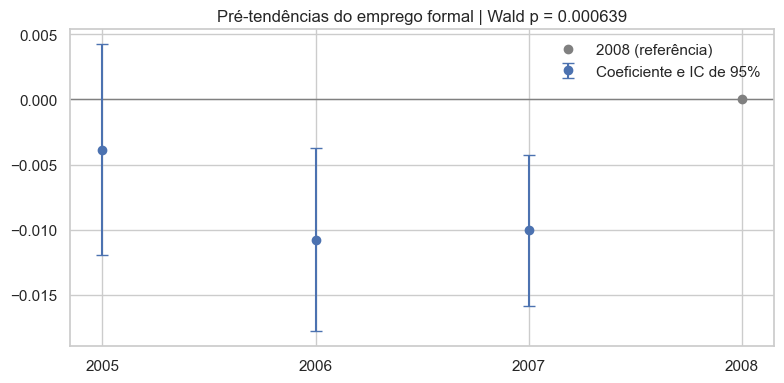

In [220]:
coef_pre = resultado_pre.params.loc[termos_pre]
ic_pre = resultado_pre.conf_int().loc[termos_pre]
assert np.isfinite(ic_pre).all().all()

fig, ax = plt.subplots(figsize=(8, 4))
ax.axhline(0, color="gray", linewidth=1)
ax.errorbar(
    anos_pre[:-1], coef_pre,
    yerr=[coef_pre - ic_pre["lower"], ic_pre["upper"] - coef_pre],
    fmt="o", capsize=4, label="Coeficiente e IC de 95%",
)
ax.plot(2008, 0, "o", color="gray", label="2008 (referência)")
ax.set(xticks=anos_pre, 
    # xlabel="Ano", ylabel="Diferença no log do emprego por 1 DP de exposição",
       title=f"Pré-tendências do emprego formal | Wald p = {teste_pre.pval:.3g}")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

##### Pré-tendências da massa salarial real

A proxy da massa salarial de dezembro é o estoque de vínculos ativos em 31 de dezembro multiplicado pela remuneração média de dezembro da RAIS. Aplicamos o fator de IPCA de dezembro de cada ano para expressar essa proxy em reais de dezembro de 2008. A medida representa a folha mensal aproximada em dezembro.

Seguimos a especificação do emprego formal. Usamos o log da proxy, efeitos fixos de município e ano, erros-padrão agrupados por município e 2008 como referência. A amostra inclui municípios com exposição vinculada e com estoque e remuneração positivos nos quatro anos de 2005 a 2008.

In [223]:
anos_pre_massa = [2005, 2006, 2007, 2008]
ipca_dezembro_pre = df_ipca.loc[
    df_ipca["ano"].isin(anos_pre_massa) & df_ipca["mes"].eq(12),
    ["ano", "fator_deflacao_dez_2008"],
].copy()

In [224]:
assert set(ipca_dezembro_pre["ano"]) == set(anos_pre_massa)
assert ipca_dezembro_pre["ano"].is_unique
fatores_dezembro_pre = ipca_dezembro_pre["fator_deflacao_dez_2008"]
assert np.isfinite(fatores_dezembro_pre).all() and fatores_dezembro_pre.gt(0).all()
assert np.isclose(ipca_dezembro_pre.loc[
    ipca_dezembro_pre["ano"].eq(2008), "fator_deflacao_dez_2008"
].item(), 1)

In [225]:
amostra_pre_massa = (
    painel_2005_2013["ano"].isin(anos_pre_massa)
    & painel_2005_2013["merge_exposicao"].eq("both")
    & painel_2005_2013["estoque_emprego"].gt(0)
    & painel_2005_2013["valor_remuneracao_dezembro"].gt(0)
)
pre_massa = painel_2005_2013.loc[amostra_pre_massa].merge(
    ipca_dezembro_pre, on="ano", how="left", validate="many_to_one"
)
anos_validos_massa = pre_massa.groupby("id_municipio")["ano"].transform("nunique")
pre_massa = pre_massa.loc[anos_validos_massa.eq(len(anos_pre_massa))].copy()

In [226]:
pre_massa["massa_salarial_proxy_real"] = (
    pre_massa["estoque_emprego"]
    * pre_massa["valor_remuneracao_dezembro"]
    * pre_massa["fator_deflacao_dez_2008"]
)
pre_massa["ln_massa_salarial"] = np.log(pre_massa["massa_salarial_proxy_real"])

In [227]:
assert set(pre_massa["ano"]) == set(anos_pre_massa)
assert not pre_massa.duplicated(["id_municipio", "ano"]).any()
assert np.isfinite(pre_massa[["ln_massa_salarial", "expo_padroniz_Z_i"]]).all().all()
assert pre_massa["expo_padroniz_Z_i"].nunique() > 1
print("Municípios nos quatro anos:", pre_massa["id_municipio"].nunique())

Municípios nos quatro anos: 5550


In [228]:
termos_pre_massa = []
for ano in anos_pre_massa[:-1]:
    termo = f"expo_{ano}"
    pre_massa[termo] = pre_massa["expo_padroniz_Z_i"] * pre_massa["ano"].eq(ano)
    termos_pre_massa.append(termo)

pre_massa_indexado = pre_massa.set_index(["id_municipio", "ano"])
modelo_pre_massa = PanelOLS(
    pre_massa_indexado["ln_massa_salarial"], pre_massa_indexado[termos_pre_massa],
    entity_effects=True, time_effects=True,
)
resultado_pre_massa = modelo_pre_massa.fit(cov_type="clustered", cluster_entity=True)

In [229]:
teste_pre_massa = resultado_pre_massa.wald_test(
    formula=[f"{termo} = 0" for termo in termos_pre_massa]
)
print(teste_pre_massa)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 18.6415
P-value: 0.0003
Distributed: chi2(3)


In [230]:
alpha_pre_massa = 0.05

if teste_pre_massa.pval >= alpha_pre_massa:
    print("Ao nível de 5%, o teste de Wald não rejeitou H₀. "
          "Os coeficientes pré-PSI são conjuntamente compatíveis com zero.")
elif teste_pre_massa.pval < alpha_pre_massa:
    print("Ao nível de 5%, o teste de Wald rejeitou H₀. "
          "Há evidência de que a trajetória da proxy de massa salarial real "
          "já diferia conforme a exposição ao Finame antes do PSI.")

Ao nível de 5%, o teste de Wald rejeitou H₀. Há evidência de que a trajetória da proxy de massa salarial real já diferia conforme a exposição ao Finame antes do PSI.


Cada ponto estima a diferença na variação do log da proxy de massa salarial real, em relação a 2008, associada a um desvio-padrão a mais de exposição. As barras mostram intervalos de confiança de 95%.

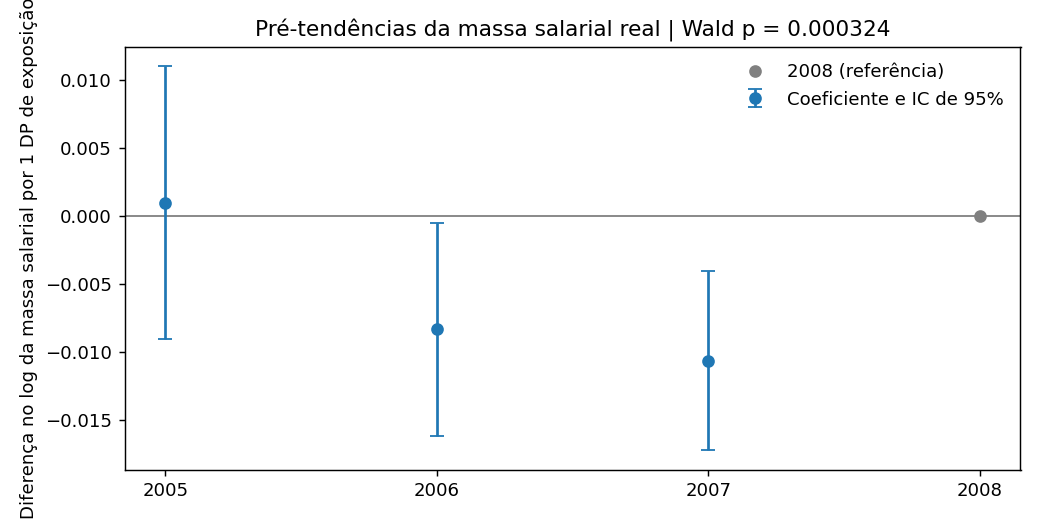

In [231]:
coef_pre_massa = resultado_pre_massa.params.loc[termos_pre_massa]
ic_pre_massa = resultado_pre_massa.conf_int().loc[termos_pre_massa]
assert np.isfinite(ic_pre_massa).all().all()

fig_massa, ax_massa = plt.subplots(figsize=(8, 4))
ax_massa.axhline(0, color="gray", linewidth=1)
ax_massa.errorbar(
    anos_pre_massa[:-1], coef_pre_massa,
    yerr=[coef_pre_massa - ic_pre_massa["lower"], ic_pre_massa["upper"] - coef_pre_massa],
    fmt="o", capsize=4, label="Coeficiente e IC de 95%",
)
ax_massa.plot(2008, 0, "o", color="gray", label="2008 (referência)")
ax_massa.set_xticks(anos_pre_massa)
ax_massa.set_ylabel("Diferença no log da massa salarial por 1 DP de exposição")
ax_massa.set_title(f"Pré-tendências da massa salarial real | Wald p = {teste_pre_massa.pval:.3g}")
ax_massa.legend(frameon=False)
fig_massa.tight_layout()
plt.show()